# Laboratorio 4: Segmentación de imágenes - Caso DermAlpes

**Caso:** DermAlpes, herramienta de apoyo para delimitar automáticamente lesiones de piel en imágenes dermatoscópicas.

**Integrantes:** Juan Camilo Panadero - Jose Luis Parra

**Objetivo:** Construir y evaluar un método de segmentación no supervisada para delimitar lesiones de piel mediante K-medias, representando cada píxel con sus características de color y posición. El laboratorio incluye la preparación de las imágenes y máscaras, la exploración de los pesos de color y posición, la selección de `K` mediante el coeficiente de silueta y el análisis crítico de las limitaciones del método.

---

## Actividad 1: pipeline de preparación y representación

Aunque las carpetas contienen el conjunto completo de 900 imágenes de ISIC 2016, este laboratorio utiliza únicamente las 20 imágenes indicadas en el enunciado: 15 para ajuste y 5 para prueba. Las máscaras de referencia se reservan para evaluar las máscaras estimadas; no se utilizan para construir la representación de los píxeles.

### Justificación del protocolo

La separación entre ajuste y prueba evita evaluar el método sobre imágenes que participaron en la toma de decisiones. Las 15 imágenes de ajuste se utilizarán para explorar los pesos de color y posición y seleccionar `K`; las 5 imágenes de prueba permanecerán aisladas hasta la evaluación final. Esta separación permite obtener una estimación más honesta de la capacidad de generalización del método.

In [20]:

from pathlib import Path

# NumPy representa las imágenes y las características como arreglos numéricos.
import numpy as np
import matplotlib.pyplot as plt
# Pillow se utiliza para leer las imágenes y las máscaras.
from PIL import Image
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Se intenta trabajar desde la carpeta del notebook; el segundo caso permite
# ejecutar esta celda desde la raíz del repositorio.
RUTA_LAB = Path.cwd()
if not (RUTA_LAB / "ISBI2016_ISIC_Part1_Training_Data").is_dir():
    RUTA_LAB = RUTA_LAB / "202620" / "Laboratorios" / "L4"
RUTA_IMAGENES = RUTA_LAB / "ISBI2016_ISIC_Part1_Training_Data"
RUTA_MASCARAS = RUTA_LAB / "ISBI2016_ISIC_Part1_Training_GroundTruth"

# Se reduce la resolución para que K-medias sea ejecutable.
# Pillow expresa el tamaño como (ancho, alto).
TAMANO_IMAGEN = (256, 256)

# Estas 15 imágenes se usan para explorar y seleccionar la configuración.
IDS_AJUSTE = [
    "ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094",
    "ISIC_0000108", "ISIC_0000114", "ISIC_0000116", "ISIC_0000122",
    "ISIC_0000133", "ISIC_0000137", "ISIC_0000150", "ISIC_0000153",
    "ISIC_0000156", "ISIC_0000157", "ISIC_0000112",
]
# Estas 5 imágenes se reservan para la evaluación final.
IDS_PRUEBA = [
    "ISIC_0000087", "ISIC_0000105", "ISIC_0000110", "ISIC_0000123",
    "ISIC_0000128",
]
# La lista completa permite verificar las 20 parejas imagen-máscara.
IDS_USADOS = IDS_AJUSTE + IDS_PRUEBA




## Carga y preparación de imágenes y máscaras

Los canales RGB y las coordenadas se normalizan a `[0, 1]`. Las máscaras se convierten de `0/255` a `0/1`. Si fuera necesario redimensionar una máscara, se utiliza vecino más cercano para conservar su naturaleza binaria.

### Decisiones de preparación

Las imágenes originales tienen una resolución alta para el número de agrupamientos que se deben explorar. Por esta razón se redimensionan a `256 × 256`, lo que produce `65.536` píxeles por imagen en lugar de varios millones. Esta decisión hace viable el experimento en memoria y tiempo, aunque puede eliminar detalles pequeños de las lesiones; por ello debe considerarse como una limitación del análisis.

La imagen RGB se redimensiona con `LANCZOS`, apropiado para valores continuos de color. La máscara se redimensiona con vecino más cercano, porque sus valores representan categorías y no deben convertirse en tonos intermedios. Después se binariza explícitamente para garantizar que solo contenga `0` y `1`.

In [21]:
# Construye la ruta de la imagen a partir de su identificador ISIC.
def ruta_imagen(image_id):
    return RUTA_IMAGENES / f"{image_id}.jpg"


# Las máscaras tienen el mismo identificador y el sufijo _Segmentation.
def ruta_mascara(image_id):
    return RUTA_MASCARAS / f"{image_id}_Segmentation.png"


def cargar_imagen(image_id, tamano=TAMANO_IMAGEN):
    """Carga una imagen RGB y la redimensiona al tamaño indicado."""
    # Se informa explícitamente si falta un archivo seleccionado.
    ruta = ruta_imagen(image_id)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró la imagen: {ruta}")
    # Convertir a RGB garantiza tres canales aunque el archivo tenga otro modo.
    with Image.open(ruta) as imagen:
        imagen = imagen.convert("RGB")
        if tamano is not None and imagen.size != tamano:
            imagen = imagen.resize(tamano, resample=Image.Resampling.LANCZOS)
        return np.asarray(imagen)


def cargar_mascara(image_id, tamano=None):
    """Carga, redimensiona opcionalmente y binariza la máscara de referencia."""
    ruta = ruta_mascara(image_id)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró la máscara: {ruta}")
    
    # L convierte la máscara a escala de grises, con un único canal.
    with Image.open(ruta) as mascara:
        mascara = mascara.convert("L")
        # El vecino más cercano conserva los valores discretos de la máscara.
        if tamano is not None and mascara.size != tamano:
            mascara = mascara.resize(tamano, resample=Image.Resampling.NEAREST)
        valores = np.asarray(mascara)

    # Convierte los valores originales 0/255 en etiquetas binarias 0/1.
    return (valores > 0).astype(np.uint8)


def validar_pares(image_ids):
    """Verifica que cada imagen seleccionada tenga su máscara correspondiente."""
    # La máscara solo se valida aquí; no participa en la representación de X.
    for image_id in image_ids:
        imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
        mascara = cargar_mascara(image_id, tamano=TAMANO_IMAGEN)
        if imagen.shape[:2] != mascara.shape:
            raise ValueError(f"Dimensiones incompatibles para {image_id}")
        if not np.isin(mascara, [0, 1]).all():
            raise ValueError(f"La máscara de {image_id} no es binaria")


validar_pares(IDS_USADOS)
print(f"Pares imagen-máscara validados: {len(IDS_USADOS)}")
print(f"Imágenes de ajuste: {len(IDS_AJUSTE)} | Imágenes de prueba: {len(IDS_PRUEBA)}")


Pares imagen-máscara validados: 20
Imágenes de ajuste: 15 | Imágenes de prueba: 5


## Representación `[beta·R, beta·G, beta·B, lambda·x, lambda·y]`

Cada fila de la matriz representa un píxel. `x` aumenta de izquierda a derecha y `y` aumenta de arriba hacia abajo. La función conserva por separado la forma `(H, W)` de la imagen para poder reconstruir posteriormente las etiquetas de K-medias como una máscara.

La representación combina apariencia y ubicación mediante:

`[beta·R, beta·G, beta·B, lambda·x, lambda·y]`

El parámetro `beta` controla la influencia del color y `lambda` controla la influencia espacial. Como todas las variables base se encuentran en `[0, 1]`, la razón `lambda/beta` determina el peso relativo entre ambos tipos de información. Si `lambda=0`, K-medias agrupa únicamente por color; si `beta=0`, agrupa únicamente por posición. No se permite que ambos sean cero porque en ese caso todos los píxeles tendrían la misma representación.

La matriz resultante tiene una fila por píxel y cinco columnas. Por ejemplo, para una imagen de `256 × 256`, su forma es `(65536, 5)`. La máscara de referencia no participa en esta transformación: se mantiene separada para evitar fuga de información.

In [22]:
def representar_imagen(imagen, beta=1.0, lambda_=1.0):
    """Construye una matriz de características con una fila por píxel."""
    imagen = np.asarray(imagen)
    if imagen.ndim != 3 or imagen.shape[2] != 3:
        raise ValueError("La imagen debe tener forma (alto, ancho, 3)")
    if beta < 0 or lambda_ < 0 or (beta == 0 and lambda_ == 0):
        raise ValueError("beta y lambda deben ser no negativos y no ambos cero")

    alto, ancho, _ = imagen.shape
    # Los canales RGB pasan de [0, 255] a [0, 1].
    colores = imagen.astype(np.float32) / 255.0
    # x representa columnas y y representa filas, ambas normalizadas a [0, 1].
    x = np.linspace(0.0, 1.0, ancho, dtype=np.float32)
    y = np.linspace(0.0, 1.0, alto, dtype=np.float32)
    coordenada_x, coordenada_y = np.meshgrid(x, y)

    # Cada fila final corresponde a un píxel y contiene cinco características.
    caracteristicas = np.column_stack([
    # ravel aplana cada canal siguiendo el mismo orden de píxeles.
        beta * colores[:, :, 0].ravel(),
        beta * colores[:, :, 1].ravel(),
        beta * colores[:, :, 2].ravel(),
        lambda_ * coordenada_x.ravel(),
        lambda_ * coordenada_y.ravel(),
    ])
    return caracteristicas.astype(np.float32)


def crear_pipeline(beta=1.0, lambda_=1.0):
    """Crea el pipeline parametrizable solicitado en la actividad."""
    # FunctionTransformer adapta nuestra función al formato de Pipeline.
    return Pipeline([
    # K-means devuelve etiquetas en una dimensión; aquí recuperamos la imagen.
        (
            "representacion",
            FunctionTransformer(
                lambda imagen: representar_imagen(imagen, beta, lambda_),
                validate=False,
            ),
        ),
    ])


def reconstruir_mascara(etiquetas, forma):
    """Devuelve las etiquetas 1D de los píxeles con forma (alto, ancho)."""
    alto, ancho = forma
    etiquetas = np.asarray(etiquetas)
    if etiquetas.size != alto * ancho:
        raise ValueError("El número de etiquetas no coincide con la imagen")
    return etiquetas.reshape((alto, ancho))


## Verificación con una imagen de ajuste

Se prueba una configuración que combina color y posición. La matriz resultante queda lista para utilizarse como entrada de `KMeans` en la Actividad 2.

Esta sección funciona como una prueba de calidad del pipeline, no como una evaluación de segmentación. Se verifica que la imagen y la máscara puedan cargarse, que tengan dimensiones compatibles, que la matriz tenga cinco características por píxel y que la máscara conserve los valores binarios. La visualización permite confirmar que la imagen y la máscara pertenecen al mismo identificador y que no quedaron invertidas o desalineadas.

In [23]:
# Se verifica una imagen de ajuste sin consultar la máscara para construir X.
image_id = IDS_AJUSTE[0]
imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
mascara_referencia = cargar_mascara(
    image_id,
    tamano=TAMANO_IMAGEN,
)

# Esta configuración combina color y posición.
beta = 1.0
lambda_ = 0.5
pipeline = crear_pipeline(beta=beta, lambda_=lambda_)
# X será la entrada de KMeans en la Actividad 2.
X = pipeline.transform(imagen)

assert X.shape == (imagen.shape[0] * imagen.shape[1], 5)
assert mascara_referencia.shape == imagen.shape[:2]
assert np.isin(mascara_referencia, [0, 1]).all()

print(f"Imagen: {image_id}")
print(f"Dimensiones: {imagen.shape[0]} x {imagen.shape[1]}")
print(f"Matriz de representación: {X.shape}")
print(f"Rango de colores normalizados: [{imagen.min() / 255:.3f}, {imagen.max() / 255:.3f}]")
print(f"Valores de la máscara: {np.unique(mascara_referencia)}")


Imagen: ISIC_0000085
Dimensiones: 256 x 256
Matriz de representación: (65536, 5)
Rango de colores normalizados: [0.000, 0.847]
Valores de la máscara: [0 1]


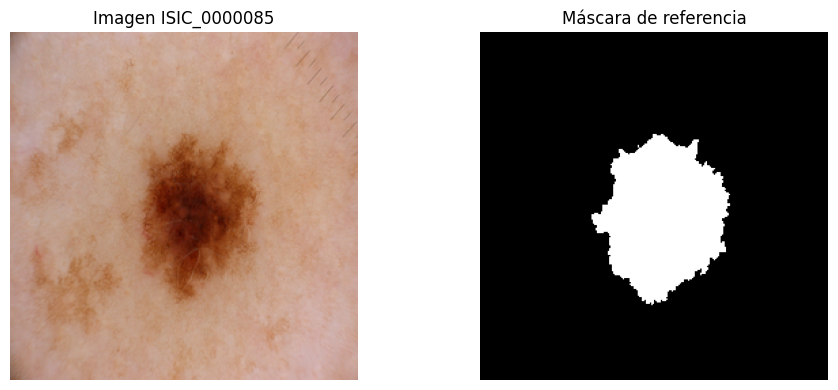

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(imagen)
axes[0].set_title(f"Imagen {image_id}")
axes[1].imshow(mascara_referencia, cmap="gray")
axes[1].set_title("Máscara de referencia")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## Actividad 2: agrupación y selección de K

Se exploran diez razones distintas entre posición y color. Para cada combinación se entrenan modelos K-medias con `K` entre 2 y 8. El coeficiente de silueta se calcula sobre una muestra reproducible de píxeles y se utiliza para seleccionar el mejor valor de `K`. Solo se usan las 15 imágenes de ajuste.

### Justificación de la exploración

Se incluyen los casos extremos de solo color y solo posición, además de configuraciones intermedias y configuraciones donde la posición tiene mayor peso. Esto permite observar cómo cambia la geometría del espacio de características cuando se modifica `lambda/beta`. Multiplicar simultáneamente `beta` y `lambda` por una misma constante no constituye una configuración nueva, porque conserva las distancias relativas; por eso se comparan razones diferentes.

En las configuraciones que utilizan color se fija `beta=1` como valor de referencia y se modifica `lambda` para controlar directamente la razón `lambda/beta`. Esta elección no significa que el color tenga un valor universal o que se haya ignorado la posibilidad de cambiar su escala; evita repetir configuraciones equivalentes. Por ejemplo, `(beta=1, lambda=0.5)` y `(beta=2, lambda=1)` tienen la misma razón y producen las mismas asignaciones de K-medias, salvo diferencias numéricas menores. La única excepción es el caso de solo posición, donde se establece `beta=0` para eliminar completamente las características de color.

K-medias es no supervisado: aprende los centroides y asigna grupos usando únicamente la matriz `X`. Las máscaras de referencia no se usan para ajustar el modelo ni para seleccionar `K`. En esta actividad los números de grupo no se interpretan todavía como fondo o lesión; esa decisión corresponde a la construcción de la máscara en una etapa posterior.

El coeficiente de silueta mide qué tan cerca está cada píxel de su propio grupo frente a los demás grupos. Valores cercanos a `1` indican grupos compactos y separados; valores cercanos a `0` indican solapamiento, y valores negativos sugieren asignaciones problemáticas. Como cada imagen tiene muchos píxeles, se utiliza una muestra de hasta 5.000 observaciones con semilla `42`, de modo que el cálculo sea ejecutable y reproducible.

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Las parejas (beta, lambda) tienen razones lambda/beta distintas.
# Se incluyen explícitamente los casos de solo color y solo posición.
CONFIGURACIONES = [
    {"beta": 1.0, "lambda_": 0.0, "nombre": "solo_color"},
    {"beta": 1.0, "lambda_": 0.1, "nombre": "lambda_beta_0.1"},
    {"beta": 1.0, "lambda_": 0.25, "nombre": "lambda_beta_0.25"},
    {"beta": 1.0, "lambda_": 0.5, "nombre": "lambda_beta_0.5"},
    {"beta": 1.0, "lambda_": 0.75, "nombre": "lambda_beta_0.75"},
    {"beta": 1.0, "lambda_": 1.0, "nombre": "lambda_beta_1.0"},
    {"beta": 1.0, "lambda_": 2.0, "nombre": "lambda_beta_2.0"},
    {"beta": 1.0, "lambda_": 4.0, "nombre": "lambda_beta_4.0"},
    {"beta": 1.0, "lambda_": 8.0, "nombre": "lambda_beta_8.0"},
    {"beta": 0.0, "lambda_": 1.0, "nombre": "solo_posicion"},
]
VALORES_K = range(2, 9)
TAMANO_MUESTRA_SILUETA = 5000
SEMILLA_MUESTRA = 42
SEMILLA_KMEANS = 42

# Se guardan los modelos para reutilizar sus grupos en la Actividad 3.
MODELOS_ACTIVIDAD_2 = {}


def indices_muestra(n_elementos, tamano, semilla):
    """Selecciona índices sin reemplazo de forma reproducible."""
    rng = np.random.default_rng(semilla)
    cantidad = min(tamano, n_elementos)
    return rng.choice(n_elementos, size=cantidad, replace=False)


def evaluar_kmeans_imagen(image_id, configuracion):
    """Calcula la silueta para K=2,...,8 en una imagen de ajuste."""
    imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
    X_imagen = crear_pipeline(
        beta=configuracion["beta"],
        lambda_=configuracion["lambda_"],
    ).transform(imagen)
    indices = indices_muestra(
        len(X_imagen), TAMANO_MUESTRA_SILUETA, SEMILLA_MUESTRA
    )
    X_muestra = X_imagen[indices]
    # Las imágenes tienen millones de píxeles; para explorar K se ajusta
    # K-means sobre la misma muestra reproducible usada por la silueta.
    X_entrenamiento = X_muestra
    resultados = []

    for k in VALORES_K:
        modelo = KMeans(
            n_clusters=k,
            random_state=SEMILLA_KMEANS,
            n_init=10,
        )
        # Se ajusta K-medias únicamente con características, sin máscaras.
        etiquetas = modelo.fit_predict(X_entrenamiento)
        MODELOS_ACTIVIDAD_2[(image_id, configuracion["nombre"], k)] = modelo
        silueta = silhouette_score(
            X_muestra,
            etiquetas,
            metric="euclidean",
        )
        resultados.append({
            "imagen": image_id,
            "configuracion": configuracion["nombre"],
            "beta": configuracion["beta"],
            "lambda_": configuracion["lambda_"],
            "K": k,
            "silueta": silueta,
            "muestra_silueta": len(indices),
            "semilla_muestra": SEMILLA_MUESTRA,
        })
    return resultados


In [26]:
# Se ejecuta el experimento sobre las 15 imágenes de ajuste.
resultados_actividad_2 = []
for image_id in IDS_AJUSTE:
    for configuracion in CONFIGURACIONES:
        resultados_actividad_2.extend(
            evaluar_kmeans_imagen(image_id, configuracion)
        )

tabla_silueta = pd.DataFrame(resultados_actividad_2)
mejor_k_por_imagen = (
    tabla_silueta.loc[
        tabla_silueta.groupby(["imagen", "configuracion"])["silueta"].idxmax()
    ]
    .sort_values(["configuracion", "imagen"])
    .reset_index(drop=True)
)

promedio_configuraciones = (
    mejor_k_por_imagen.groupby(
        ["configuracion", "beta", "lambda_"]
    )["silueta"]
    .mean()
    .sort_values(ascending=False)
    .rename("silueta_promedio")
    .reset_index()
)

print(f"Filas evaluadas: {len(tabla_silueta)}")
print(f"Muestra por silueta: hasta {TAMANO_MUESTRA_SILUETA} píxeles")
print(f"Semilla de muestra: {SEMILLA_MUESTRA}")
display(promedio_configuraciones)


Filas evaluadas: 1050
Muestra por silueta: hasta 5000 píxeles
Semilla de muestra: 42


,configuracion,beta,lambda_,silueta_promedio
0,solo_color,1.0,0.00,0.737515
1,lambda_beta_0.1,1.0,0.10,0.704221
2,lambda_beta_0.25,1.0,0.25,0.612231
3,lambda_beta_0.5,1.0,0.50,0.490475
4,lambda_beta_0.75,1.0,0.75,0.444762
5,lambda_beta_1.0,1.0,1.00,0.441057
6,lambda_beta_2.0,1.0,2.00,0.428080
7,solo_posicion,0.0,1.00,0.411685
8,lambda_beta_8.0,1.0,8.00,0.408397
9,lambda_beta_4.0,1.0,4.00,0.407798


### Interpretación preliminar de los resultados

El experimento genera `15 × 10 × 7 = 1050` filas: una por cada combinación de imagen, configuración de pesos y valor de `K`. La tabla `promedio_configuraciones` resume, para cada configuración, la mejor silueta obtenida en cada imagen y luego calcula el promedio entre las 15 imágenes.

En la ejecución realizada, `solo_color` obtuvo la mayor silueta promedio (`0.737515`). Esto indica que, dentro del espacio de características utilizado, los píxeles quedan más compactos y separados cuando se agrupan principalmente por color. Al aumentar `lambda/beta`, la silueta disminuye, lo que sugiere que la posición aporta menos separación geométrica para este conjunto y estos pesos.

Esta conclusión es provisional. Una silueta alta no garantiza que un grupo corresponda a la lesión ni que la máscara tenga buen Dice: la silueta evalúa la estructura interna de los grupos, no su coincidencia con la máscara elaborada por los especialistas. Por eso la configuración seleccionada deberá contrastarse posteriormente con el criterio de construcción de la máscara, Dice, V-measure y una revisión visual de los casos de fallo.

La tabla `mejor_k_por_imagen` conserva el valor de `K` que maximizó la silueta para cada imagen y configuración. Es importante reportar esos valores y no únicamente el promedio global, porque una configuración puede tener un buen promedio y aun así fallar en imágenes particulares.

## Actividad 3: construcción de la máscara mediante color

Para cada imagen se reutiliza el modelo y el valor de `K` obtenidos en la Actividad 2. No se vuelve a entrenar K-medias para decidir cuál grupo corresponde a la lesión. Se recorren los `K` grupos encontrados, se calcula el color promedio de los píxeles de cada grupo y se selecciona como lesión el grupo con menor intensidad RGB promedio. Finalmente, los píxeles de ese grupo se convierten en `1` y los demás en `0`.

Este criterio se basa en la hipótesis de que la lesión es más oscura que la piel circundante. La máscara de referencia no participa en la selección del grupo; se utilizará posteriormente para calcular las métricas de evaluación.

In [27]:
def analizar_grupos_por_color(imagen, etiquetas):
    """Calcula la intensidad RGB promedio de cada grupo encontrado."""
    imagen_normalizada = imagen.astype(np.float32) / 255.0
    colores = imagen_normalizada.reshape(-1, 3)
    etiquetas = np.asarray(etiquetas)
    grupos = []

    # Se recorren los K grupos y se analizan solo sus píxeles.
    for grupo in np.unique(etiquetas):
        pixeles_grupo = colores[etiquetas == grupo]
        color_promedio = pixeles_grupo.mean(axis=0)
        intensidad = color_promedio.mean()
        grupos.append({
            "grupo": int(grupo),
            "R_promedio": float(color_promedio[0]),
            "G_promedio": float(color_promedio[1]),
            "B_promedio": float(color_promedio[2]),
            "intensidad_promedio": float(intensidad),
            "numero_pixeles": int(len(pixeles_grupo)),
        })

    return pd.DataFrame(grupos)


def construir_mascara_por_color(image_id, configuracion="solo_color"):
    """Selecciona el grupo más oscuro y lo convierte en máscara binaria."""
    seleccion = mejor_k_por_imagen.query(
        "imagen == @image_id and configuracion == @configuracion"
    )
    if seleccion.empty:
        raise ValueError(f"No hay un K seleccionado para {image_id}")

    k = int(seleccion.iloc[0]["K"])
    clave_modelo = (image_id, configuracion, k)
    if clave_modelo not in MODELOS_ACTIVIDAD_2:
        raise RuntimeError(
            "Ejecuta primero las celdas de la Actividad 2 para guardar el modelo."
        )

    modelo = MODELOS_ACTIVIDAD_2[clave_modelo]
    imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
    configuracion_actual = next(
        item for item in CONFIGURACIONES if item["nombre"] == configuracion
    )
    X_imagen = crear_pipeline(
        beta=configuracion_actual["beta"],
        lambda_=configuracion_actual["lambda_"]
    ).transform(imagen)

    # Se asignan todos los píxeles a los grupos del modelo ya entrenado.
    etiquetas = modelo.predict(X_imagen)
    tabla_grupos = analizar_grupos_por_color(imagen, etiquetas)
    grupo_lesion = int(
        tabla_grupos.loc[tabla_grupos["intensidad_promedio"].idxmin(), "grupo"]
    )

    # El grupo más oscuro se convierte en 1; los demás, en 0.
    mascara = (etiquetas == grupo_lesion).astype(np.uint8)
    mascara = reconstruir_mascara(mascara, imagen.shape[:2])
    return imagen, mascara, tabla_grupos, k, grupo_lesion


Imagen: ISIC_0000085
K seleccionado en la Actividad 2: 2
Grupo identificado como lesión: 1


,grupo,R_promedio,G_promedio,B_promedio,intensidad_promedio,numero_pixeles
0,0,0.766818,0.608376,0.521777,0.632324,58469
1,1,0.519746,0.253263,0.122511,0.298507,7067


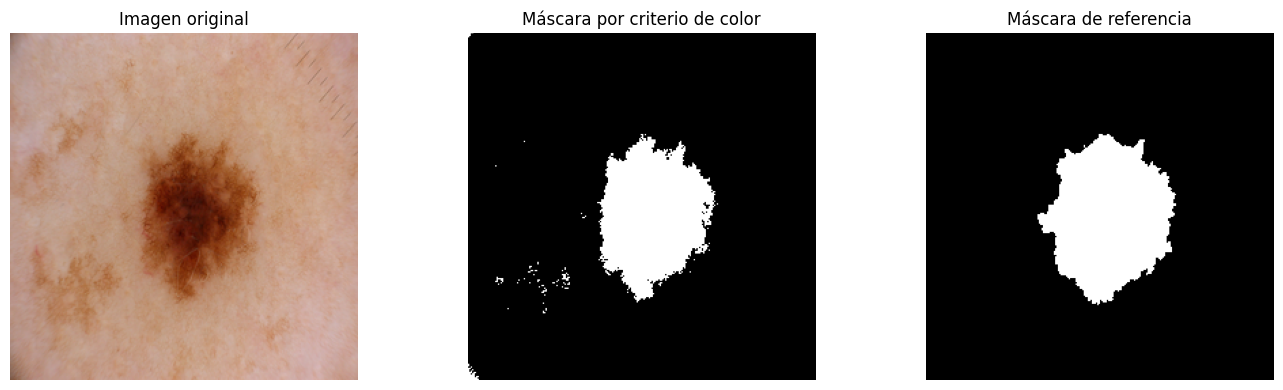

In [28]:
imagen_ejemplo, mascara_color, tabla_grupos, k_ejemplo, grupo_lesion = (
    construir_mascara_por_color(IDS_AJUSTE[0])
)

print(f"Imagen: {IDS_AJUSTE[0]}")
print(f"K seleccionado en la Actividad 2: {k_ejemplo}")
print(f"Grupo identificado como lesión: {grupo_lesion}")
display(tabla_grupos)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(imagen_ejemplo)
axes[0].set_title("Imagen original")
axes[1].imshow(mascara_color, cmap="gray")
axes[1].set_title("Máscara por criterio de color")
axes[2].imshow(cargar_mascara(
    IDS_AJUSTE[0], tamano=TAMANO_IMAGEN
), cmap="gray")
axes[2].set_title("Máscara de referencia")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


### Aplicación sobre las 15 imágenes de ajuste

La celda anterior muestra un solo caso como verificación visual. En esta celda se aplica el mismo criterio de color a todas las imágenes de ajuste y se conserva la máscara generada junto con el grupo seleccionado y el valor de `K`.

In [29]:
resultados_actividad_3_color = []
mascaras_actividad_3_color = {}

for image_id in IDS_AJUSTE:
    imagen, mascara, tabla_grupos, k, grupo_lesion = construir_mascara_por_color(
        image_id
    )
    mascaras_actividad_3_color[image_id] = mascara
    fila_grupo = tabla_grupos.loc[
        tabla_grupos["grupo"] == grupo_lesion
    ].iloc[0]
    resultados_actividad_3_color.append({
        "imagen": image_id,
        "K": k,
        "grupo_lesion": grupo_lesion,
        "intensidad_grupo_lesion": fila_grupo["intensidad_promedio"],
        "pixeles_mascara": int(mascara.sum()),
    })

tabla_actividad_3_color = pd.DataFrame(resultados_actividad_3_color)
print(f"Imágenes procesadas: {len(tabla_actividad_3_color)}")
display(tabla_actividad_3_color)


Imágenes procesadas: 15


,imagen,K,grupo_lesion,intensidad_grupo_lesion,pixeles_mascara
0,ISIC_0000085,2,1,0.298507,7067
1,ISIC_0000086,2,1,0.362802,13405
2,ISIC_0000089,2,1,0.270578,7106
3,ISIC_0000094,2,0,0.551302,10155
4,ISIC_0000108,2,1,0.275159,10009
5,ISIC_0000114,2,1,0.427300,4501
6,ISIC_0000116,2,1,0.447716,14621
7,ISIC_0000122,2,1,0.491624,21418
8,ISIC_0000133,2,1,0.337589,10949
9,ISIC_0000137,2,0,0.371027,15087


### Análisis de los resultados

Los resultados muestran que el criterio de color se aplicó correctamente a las 15 imágenes de ajuste. Para cada imagen se recorrieron los grupos generados por K-means y se seleccionó como lesión el grupo con menor intensidad RGB promedio, ya que representa la región más oscura de la imagen. Posteriormente, todos los píxeles pertenecientes a ese grupo recibieron el valor `1` en la máscara, mientras que los píxeles de los demás grupos recibieron `0`. El número de píxeles seleccionados varía entre imágenes porque el tamaño de la región oscura no es igual en todos los casos. Sin embargo, una menor intensidad no garantiza por sí sola que el grupo corresponda exactamente a la lesión, pues también puede incluir sombras, bordes u otras regiones oscuras. Por esta razón, estos resultados deben contrastarse con las máscaras de referencia mediante métricas como Dice y V-measure, además de una inspección visual, tal y como se hará en la proxima actividad